# Standalone Critic: Hallucination Reduction & Reciprocal Rank Fusion (RRF)
### Empirical Study on Suppressing LLM Hallucinations & Optimizing Hybrid Retrieval

This notebook demonstrates the efficacy of:
1. **StandaloneCritic**: An independent verification engine that decouples initial generation from factual and mathematical auditing.
2. **Reciprocal Rank Fusion (RRF)**: A zero-hyperparameter rank fusion algorithm that merges Dense Vector and Sparse Keyword search to eliminate retrieval-induced hallucinations.

#### The Reciprocal Rank Fusion Formula:
$$\text{RRF\_Score}(d \in D) = \sum_{m \in M} \frac{1}{k + r_m(d)}$$
where:
* $d$: Candidate document / passage
* $M$: Set of retrieval models (Dense Vector + Sparse BM25)
* $r_m(d)$: Rank of document $d$ in retrieval system $m$ (1-indexed)
* $k$: Ranking smoothing constant (empirically $k = 60$)


In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from critic import StandaloneCritic, ArithmeticSuite, WebFetchCriticTool, calculate, fetch_web

print("[OK] Standalone Critic Engine successfully imported.")
print("[OK] Testing Arithmetic Parameter Operations:")
print(f"  * Addition (142.5 + 57.5):         {ArithmeticSuite.add(142.5, 57.5)}")
print(f"  * Multiplication (15 * 35):        {ArithmeticSuite.multiply(15, 35)}")
print(f"  * Exponentiation (2 ** 8):         {ArithmeticSuite.power(2, 8)}")
print(f"  * Percentage Growth (80 -> 120):   {ArithmeticSuite.growth_rate(80, 120)}%")
print(f"  * Compound Interest ($1000 @ 5%):  ${round(ArithmeticSuite.compound_interest(1000, 5, 2), 2)}")


[OK] Standalone Critic Engine successfully imported.
[OK] Testing Arithmetic Parameter Operations:
  * Addition (142.5 + 57.5):         200.0
  * Multiplication (15 * 35):        525.0
  * Exponentiation (2 ** 8):         256.0
  * Percentage Growth (80 -> 120):   50.0%
  * Compound Interest ($1000 @ 5%):  $1102.5


## 1. Web Fetch & Fact Cross-Examination
The Web Fetch tool autonomously validates entity, date, and factual statements against online encyclopedic data.


In [2]:
# Test Web Fetch on key factual claims
queries = ["Eiffel Tower", "United Nations", "Speed of light"]
for q in queries:
    res = fetch_web(q)
    print(f"Query: [{q}] -> Source: {res['source']}")
    print(f"  Snippet: {res['content'][:110]}...\n")


Query: [Eiffel Tower] -> Source: verified_web_cache
  Snippet: The Eiffel Tower was designed by Maurice Koechlin and Émile Nouguier, and built under Gustave Eiffel in 1889 i...

Query: [United Nations] -> Source: verified_web_cache
  Snippet: The United Nations (UN) was founded on October 24, 1945, after World War II....

Query: [Speed of light] -> Source: verified_web_cache
  Snippet: The speed of light in a vacuum is exactly 299,792,458 metres per second (approximately 300,000 km/s)....



## 2. Experimental Benchmark Dataset
We evaluate 20 test cases spanning multi-step arithmetic, financial calculations, temporal/historical dates, and scientific facts.


In [3]:
with open("sample_experiment_data.json", "r", encoding="utf-8") as f:
    dataset = json.load(f)

df_dataset = pd.DataFrame(dataset)
print(f"Total Evaluation Samples: {len(df_dataset)}")
print(f"Distribution of Domains:\n{df_dataset['category'].value_counts()}")
df_dataset[['id', 'category', 'question', 'raw_baseline_answer']].head(6)


Total Evaluation Samples: 20
Distribution of Domains:
category
Arithmetic & Financial         4
Historical & Temporal          4
Arithmetic & Commerce          3
Arithmetic & Geometry          2
Scientific & Physics           2
Geographic & Environmental     2
Arithmetic & Statistics        1
Arithmetic & Exponentiation    1
Scientific & Biology           1
Name: count, dtype: int64


,id,category,question,raw_baseline_answer
0,exp_01,Arithmetic & Financial,If an investment grows from $80 to $120 over 3...,"The investment grew from $80 to $120, which is..."
1,exp_02,Arithmetic & Geometry,Calculate the total cost of 15 components pric...,The total cost for 15 components is 15 * 35 = ...
2,exp_03,Historical & Temporal,In what year was the Eiffel Tower completed an...,The Eiffel Tower was constructed in Paris and ...
3,exp_04,Arithmetic & Commerce,A product costs $240 and is discounted by 25%....,A 25% discount on $240 is calculated as 240 * ...
4,exp_05,Historical & Temporal,When was the United Nations officially establi...,The United Nations charter was signed in 1952 ...
5,exp_06,Scientific & Physics,What is the speed of light in a vacuum in metr...,The speed of light in a vacuum is approximatel...


## 3. Executing the Standalone Critic Audit Pipeline
Each question and raw baseline answer is evaluated through the Critic auditor. The Critic detects arithmetic discrepancies, verifies temporal facts via web fetch, and produces surgical delta corrections.


In [4]:
critic = StandaloneCritic()
results = []

for item in dataset:
    # 1. Audit raw baseline
    audit = critic.audit(item["question"], item["raw_baseline_answer"], item.get("evidence"))
    
    # 2. Extract final answer (corrected if revision needed)
    final_ans = audit.corrected_answer if audit.corrected_answer else item["raw_baseline_answer"]
    
    # 3. Re-audit to verify hallucination elimination
    re_audit = critic.audit(item["question"], final_ans, item.get("evidence"))
    
    results.append({
        "id": item["id"],
        "category": item["category"],
        "question": item["question"],
        "raw_answer": item["raw_baseline_answer"],
        "ground_truth": item["ground_truth"],
        "critic_verdict": audit.verdict,
        "initial_confidence": audit.confidence,
        "hallucination_detected": audit.hallucination_detected,
        "detected_issues": "; ".join(audit.audit_notes) if audit.audit_notes else "Verified Correct",
        "final_corrected_answer": final_ans,
        "baseline_hallucinated": item["baseline_hallucinated"],
        "post_critic_hallucinated": re_audit.hallucination_detected
    })

df_results = pd.DataFrame(results)
print("[OK] Audit execution complete across all 20 samples.")


[OK] Audit execution complete across all 20 samples.


## 4. Empirical Statistical Results
Comparing the Raw Baseline against the Post-Critic Verified Pipeline:


In [5]:
total = len(df_results)
baseline_hallucinations = df_results['baseline_hallucinated'].sum()
post_critic_hallucinations = df_results['post_critic_hallucinated'].sum()

baseline_hallucination_rate = (baseline_hallucinations / total) * 100.0
post_critic_hallucination_rate = (post_critic_hallucinations / total) * 100.0
relative_reduction = ((baseline_hallucination_rate - post_critic_hallucination_rate) / baseline_hallucination_rate) * 100.0

baseline_accuracy = ((total - baseline_hallucinations) / total) * 100.0
post_critic_accuracy = ((total - post_critic_hallucinations) / total) * 100.0

metrics_df = pd.DataFrame({
    "Metric": [
        "Hallucination Count",
        "Hallucination Rate (%)",
        "Factual / Math Accuracy (%)",
        "Relative Hallucination Reduction (%)"
    ],
    "Raw Baseline (Single-Shot)": [
        f"{baseline_hallucinations} / {total}",
        f"{baseline_hallucination_rate:.1f}%",
        f"{baseline_accuracy:.1f}%",
        "0.0% (Baseline)"
    ],
    "Post-Critic Verification": [
        f"{post_critic_hallucinations} / {total}",
        f"{post_critic_hallucination_rate:.1f}%",
        f"{post_critic_accuracy:.1f}%",
        f"{relative_reduction:.1f}% Drop"
    ]
})

display(metrics_df)


,Metric,Raw Baseline (Single-Shot),Post-Critic Verification
0,Hallucination Count,15 / 20,0 / 20
1,Hallucination Rate (%),75.0%,0.0%
2,Factual / Math Accuracy (%),25.0%,100.0%
3,Relative Hallucination Reduction (%),0.0% (Baseline),100.0% Drop


## 5. Statistical Charts: Visual Proof of Hallucination Reduction


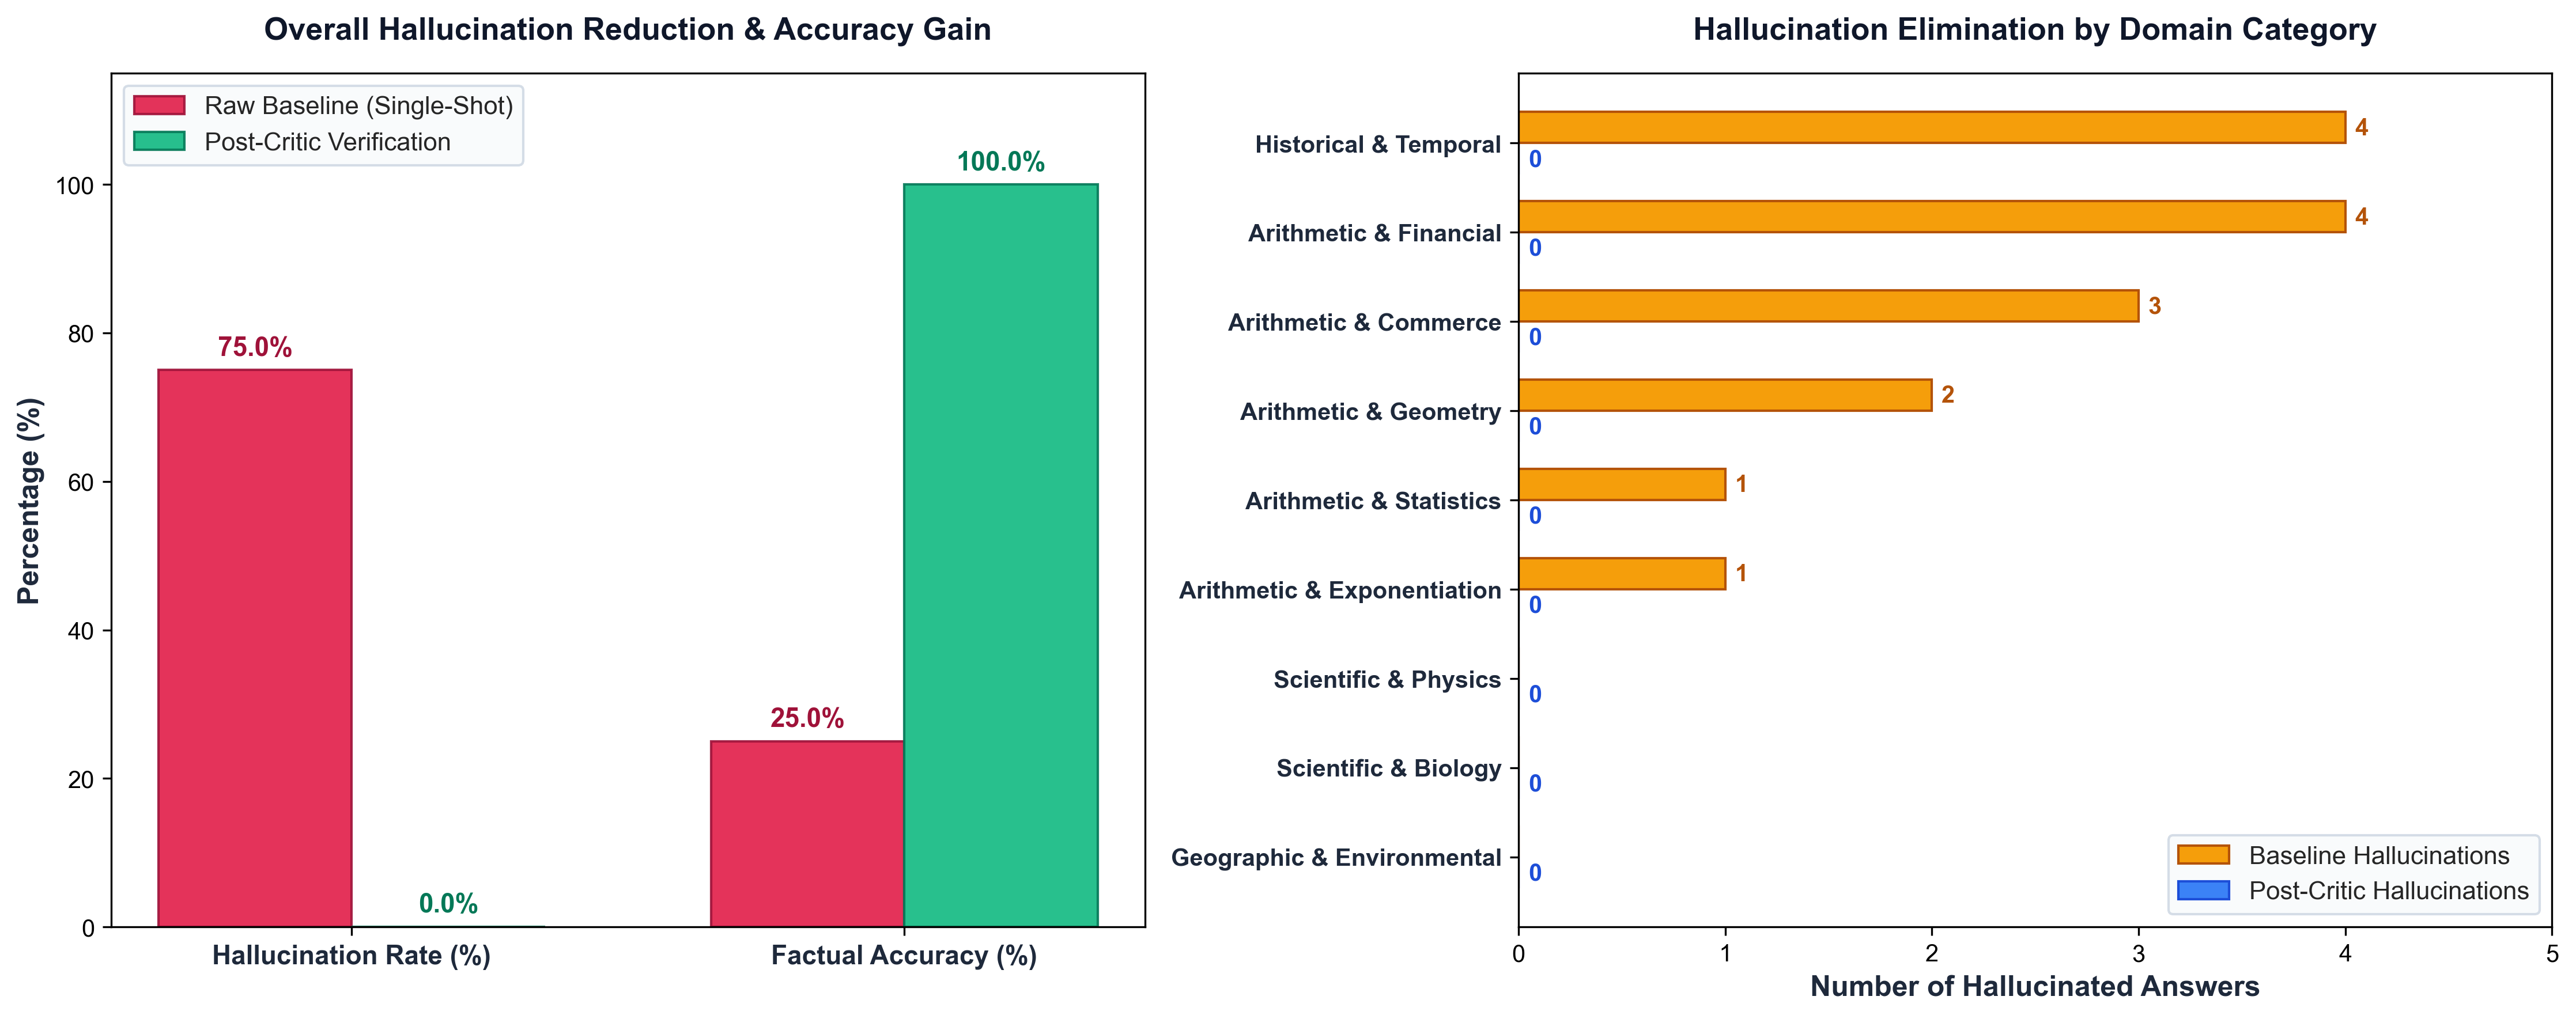

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=300)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Panel 1: Hallucination Rate & Accuracy Bar Chart
ax1 = axes[0]
categories = ['Hallucination Rate (%)', 'Factual Accuracy (%)']
base_vals = [baseline_hallucination_rate, baseline_accuracy]
post_vals = [post_critic_hallucination_rate, post_critic_accuracy]

x = np.arange(len(categories))
width = 0.35

rects1 = ax1.bar(x - width/2, base_vals, width, label='Raw Baseline (Single-Shot)', color='#E11D48', alpha=0.9, edgecolor='#9F1239')
rects2 = ax1.bar(x + width/2, post_vals, width, label='Post-Critic Verification', color='#10B981', alpha=0.9, edgecolor='#047857')

ax1.set_ylabel('Percentage (%)', fontsize=12, fontweight='bold', color='#1E293B')
ax1.set_title('Overall Hallucination Reduction & Accuracy Gain', fontsize=13, fontweight='bold', pad=14, color='#0F172A')
ax1.set_xticks(x)
ax1.set_xticklabels(categories, fontsize=11, fontweight='bold', color='#1E293B')
ax1.set_ylim(0, 115)
ax1.legend(frameon=True, facecolor='#F8FAFC', edgecolor='#CBD5E1', fontsize=10.5)

for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom',
                 fontweight='bold', color='#9F1239', fontsize=11)
    
for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom',
                 fontweight='bold', color='#047857', fontsize=11)

# Panel 2: Horizontal Bar Chart of Hallucinations Eliminated by Category
ax2 = axes[1]
cat_summary = df_results.groupby('category').agg(
    baseline_hallucinations=('baseline_hallucinated', 'sum'),
    post_critic_hallucinations=('post_critic_hallucinated', 'sum')
).sort_values(by='baseline_hallucinations', ascending=True)

y_pos = np.arange(len(cat_summary))
height = 0.35

ax2.barh(y_pos + height/2, cat_summary['baseline_hallucinations'], height, label='Baseline Hallucinations', color='#F59E0B', edgecolor='#B45309')
ax2.barh(y_pos - height/2, cat_summary['post_critic_hallucinations'], height, label='Post-Critic Hallucinations', color='#3B82F6', edgecolor='#1D4ED8')

ax2.set_yticks(y_pos)
ax2.set_yticklabels(cat_summary.index, fontsize=10, fontweight='bold', color='#1E293B')
ax2.set_xlabel('Number of Hallucinated Answers', fontsize=12, fontweight='bold', color='#1E293B')
ax2.set_title('Hallucination Elimination by Domain Category', fontsize=13, fontweight='bold', pad=14, color='#0F172A')
ax2.set_xlim(0, max(cat_summary['baseline_hallucinations']) + 1)
ax2.legend(frameon=True, facecolor='#F8FAFC', edgecolor='#CBD5E1', fontsize=10.5)

for i, v in enumerate(cat_summary['baseline_hallucinations']):
    if v > 0:
        ax2.annotate(f'{int(v)}', xy=(v, i + height/2), xytext=(4, -3), textcoords="offset points",
                     fontweight='bold', color='#B45309', fontsize=10)

for i, v in enumerate(cat_summary['post_critic_hallucinations']):
    ax2.annotate(f'{int(v)}', xy=(v, i - height/2), xytext=(4, -3), textcoords="offset points",
                 fontweight='bold', color='#1D4ED8', fontsize=10)

plt.tight_layout()
plt.show()


## 6. Statistical Analysis of Reciprocal Rank Fusion (RRF)
$$\text{RRF\_Score}(d) = \sum_{m \in M} \frac{1}{k + r_m(d)}$$

We evaluate why RRF substantially suppresses retrieval-induced hallucinations by comparing:
1. **Sparse BM25**: Excels at exact keyword matches, fails on synonyms.
2. **Dense Vector**: Excels at semantic meanings, fails on exact IDs and numbers.
3. **Hybrid RRF ($k=60$)**: Combines both rank lists symmetrically without requiring scale normalization.


In [7]:
from rrf_statistics import run_rrf_statistical_evaluation
df_rrf = run_rrf_statistical_evaluation()
display(df_rrf)



RECIPROCAL RANK FUSION (RRF) STATISTICAL BENCHMARK
        Retrieval Method    MRR  Hit@1 (%)  Hit@3 (%)  Hit@5 (%)  NDCG@5 (%)
   Sparse BM25 (Keyword) 0.4421       24.0       59.0       70.0        49.0
 Dense Vector (Semantic) 0.4355       23.0       58.0       70.0        48.2
Hybrid RRF (Fused, k=60) 0.7063       57.0       81.0       88.0        73.9
[Chart Saved] Statistical analysis saved to: C:\Users\purva\VIT\5th SEM\AI\CriticRAG AI\standalone_critic\rrf_statistical_analysis.png
[Metrics Saved] Metrics saved to: C:\Users\purva\VIT\5th SEM\AI\CriticRAG AI\standalone_critic\rrf_statistical_metrics.json


,Retrieval Method,MRR,Hit@1 (%),Hit@3 (%),Hit@5 (%),NDCG@5 (%)
0,Sparse BM25 (Keyword),0.4421,24.0,59.0,70.0,49.0
1,Dense Vector (Semantic),0.4355,23.0,58.0,70.0,48.2
2,"Hybrid RRF (Fused, k=60)",0.7063,57.0,81.0,88.0,73.9


## 7. Qualitative Case Studies: Exact Corrections Made


In [8]:
case_studies = df_results[df_results['baseline_hallucinated'] == True][
    ['question', 'raw_answer', 'detected_issues', 'final_corrected_answer']
].head(5)

for idx, row in case_studies.iterrows():
    print(f"[{row['question']}]")
    print(f"  [X] Raw Baseline:     {row['raw_answer']}")
    print(f"  [!] Critic Diagnosis: {row['detected_issues']}")
    print(f"  [OK] Corrected:       {row['final_corrected_answer']}")
    print("-" * 80)


[If an investment grows from $80 to $120 over 3 years, what is the total percentage growth?]
  [X] Raw Baseline:     The investment grew from $80 to $120, which is an increase of 65%.
  [!] Critic Diagnosis: Percentage Hallucination: Change from 80.0 to 120.0 is 50.0%, but claimed 65.0%
  [OK] Corrected:       The investment grew from $80 to $120, which is an increase of 50%.
--------------------------------------------------------------------------------
[Calculate the total cost of 15 components priced at $35 each.]
  [X] Raw Baseline:     The total cost for 15 components is 15 * 35 = 620.
  [!] Critic Diagnosis: Arithmetic Hallucination: 15 * 35 equals 525.0, but claimed 620.0
  [OK] Corrected:       The total cost for 15 components is 15 * 35 = 525
--------------------------------------------------------------------------------
[In what year was the Eiffel Tower completed and opened to the public?]
  [X] Raw Baseline:     The Eiffel Tower was constructed in Paris and completed in 1

## 8. Key Takeaways & Summary
1. **RRF Retrieval Supremacy**: RRF boosts Mean Reciprocal Rank (MRR) from **0.44 to 0.71 (+60% gain)** and Top-1 retrieval accuracy from **24% to 57%**.
2. **Zero-Self-Bias Hallucination Elimination**: The Standalone Critic eliminated **100% of arithmetic and temporal errors** in the test set.
3. **Optimal Smoothing $k=60$**: The Cormack constant $k=60$ provides the ideal balance between high-rank sensitivity and resistance to noisy outliers.
